In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor, ExtraTreesRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# 1. Data Understanding & EDA
df = pd.read_csv("laptopData.csv")
print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicates:", df.duplicated().sum())

Shape: (1303, 12)
Missing values:
 Unnamed: 0          30
Company             30
TypeName            30
Inches              30
ScreenResolution    30
Cpu                 30
Ram                 30
Memory              30
Gpu                 30
OpSys               30
Weight              30
Price               30
dtype: int64
Duplicates: 29


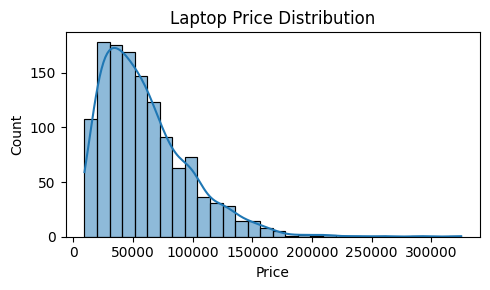

In [3]:
plt.figure(figsize=(5, 3))
sns.histplot(df["Price"].dropna(), bins=30, kde=True)
plt.title("Laptop Price Distribution")
plt.tight_layout()
plt.show()

In [4]:
# 2. Data Cleaning & Feature Engineering
df = df.drop_duplicates().dropna(subset=["Price"]).copy()
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

df["Ram_GB"] = pd.to_numeric(df["Ram"].astype(str).str.replace("GB", "", regex=False).str.strip(), errors="coerce")
df["Weight_kg"] = pd.to_numeric(df["Weight"].astype(str).str.replace("kg", "", regex=False).str.strip(), errors="coerce")
df["Inches"] = pd.to_numeric(df["Inches"], errors="coerce")
df = df.drop(columns=["Ram", "Weight"])

X = df.drop(columns=["Price"])
y = df["Price"]

In [5]:
# 3. Train/Test Split & Preprocessing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])

In [6]:
# 4. Models Comparison
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=2000),
    "ElasticNet": ElasticNet(max_iter=2000),
    "KNN Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR": SVR(),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42)
}

In [7]:
results = []
for name, reg in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", reg)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    results.append({
        "Model": name,
        "MAE": round(mean_absolute_error(y_test, y_pred), 2),
        "MSE": round(mse, 2),
        "RMSE": round(np.sqrt(mse), 2),
        "R2": round(r2_score(y_test, y_pred), 4)
    })

In [11]:
comp_df = pd.DataFrame(results).sort_values(by="R2", ascending=False)
display(comp_df)

,Model,MAE,MSE,RMSE,R2
4,KNN Regressor,10200.85,2.736337e+08,16541.88,0.8114
1,Ridge,11053.08,2.890053e+08,17000.16,0.8008
8,Gradient Boosting,11793.96,3.355230e+08,18317.29,0.7687
6,Random Forest,10172.58,3.455845e+08,18589.90,0.7618
2,Lasso,12299.37,4.287833e+08,20707.08,0.7044
10,Extra Trees,11292.92,4.308445e+08,20756.80,0.7030
0,Linear Regression,12771.61,4.717100e+08,21718.89,0.6748
5,Decision Tree,13570.61,5.296981e+08,23015.17,0.6349
9,AdaBoost,20027.14,6.188595e+08,24876.89,0.5734
3,ElasticNet,18298.37,6.724352e+08,25931.35,0.5365


In [12]:
# 5. GridSearchCV on Best Model
best_name = comp_df.iloc[0]["Model"]
best_r2_before = comp_df.iloc[0]["R2"]
param_grids = {
    "Random Forest": {"model__n_estimators": [100, 150], "model__max_depth": [None, 12]},
    "Extra Trees": {"model__n_estimators": [100, 150], "model__max_depth": [None, 12]},
    "Gradient Boosting": {"model__n_estimators": [100, 150], "model__learning_rate": [0.05, 0.1]},
    "Decision Tree": {"model__max_depth": [None, 8, 12]},
    "KNN Regressor": {"model__n_neighbors": [3, 5, 7]},
    "Ridge": {"model__alpha": [0.1, 1.0, 10.0]},
    "Lasso": {"model__alpha": [0.1, 1.0, 10.0]},
    "ElasticNet": {"model__alpha": [0.1, 1.0]},
    "SVR": {"model__C": [1.0, 10.0]},
    "AdaBoost": {"model__n_estimators": [50, 100]}
}

grid = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", models[best_name])]),
    param_grid=param_grids.get(best_name, {}),
    cv=5, scoring="r2", n_jobs=-1
)
grid.fit(X_train, y_train)
print("Best Model:", best_name)
print("best_params_:", grid.best_params_)
print("best_score_:", round(grid.best_score_, 4))

Best Model: KNN Regressor
best_params_: {'model__n_neighbors': 3}
best_score_: 0.7593


R2 Before Tuning: 0.8114 | After Tuning: 0.7851


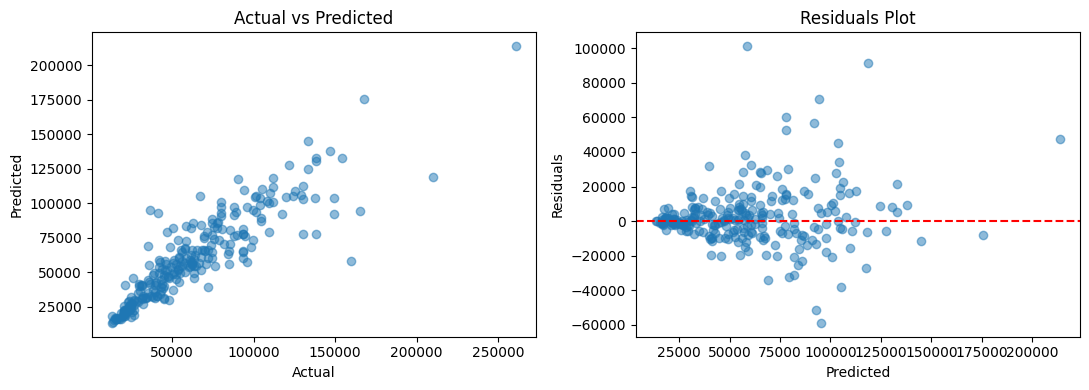

In [13]:
# 6. Final Evaluation & Plots
best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test)
print(f"R2 Before Tuning: {best_r2_before:.4f} | After Tuning: {r2_score(y_test, y_pred_best):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, y_pred_best, alpha=0.5)
axes[0].set_title("Actual vs Predicted")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")

axes[1].scatter(y_pred_best, y_test - y_pred_best, alpha=0.5)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_title("Residuals Plot")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residuals")
plt.tight_layout()
plt.show()